## Problem 18
Manual boundary extraction using binary image erosion.

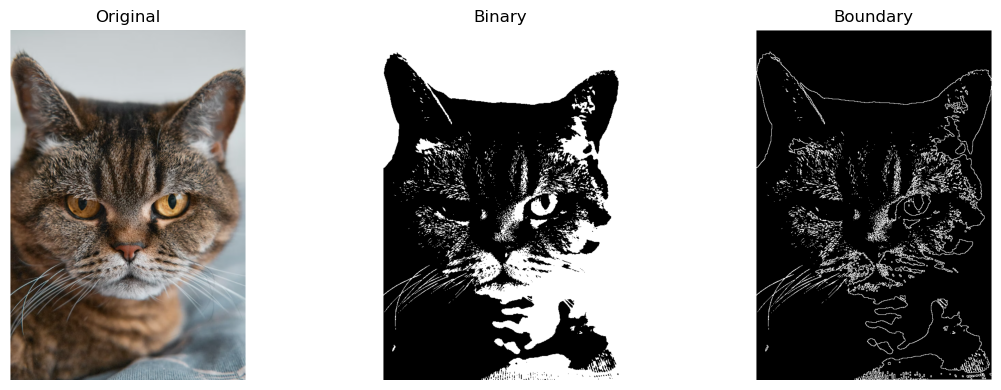

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

image = cv2.imread("cat.png")
height, width = image.shape[:2]
binary = np.zeros((height, width), dtype=np.uint8)

# Convert the image to binary manually.
for row in range(height):
    for col in range(width):
        blue = int(image[row, col, 0])
        green = int(image[row, col, 1])
        red = int(image[row, col, 2])
        gray = int(0.114 * blue + 0.587 * green + 0.299 * red)
        if gray > 127:
            binary[row, col] = 255

# Manual erosion with a 3x3 square kernel.
eroded = np.zeros((height, width), dtype=np.uint8)
for row in range(1, height - 1):
    for col in range(1, width - 1):
        keep_pixel = True
        for kernel_row in range(3):
            for kernel_col in range(3):
                if binary[row + kernel_row - 1, col + kernel_col - 1] == 0:
                    keep_pixel = False
        if keep_pixel:
            eroded[row, col] = 255

# Boundary = original binary image - eroded image.
boundary = np.zeros((height, width), dtype=np.uint8)
for row in range(height):
    for col in range(width):
        if binary[row, col] == 255 and eroded[row, col] == 0:
            boundary[row, col] = 255

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(image[:, :, ::-1])
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(boundary, cmap="gray")
plt.title("Boundary")
plt.axis("off")
plt.tight_layout()
plt.show()
